In [ ]:
import tensorflow as tf
from tensorflow import keras
print("TensorFlow version:",tf.__version__)
model=keras.Sequential([
    keras.layers.Dense(units=16,activation="relu"),
    keras.layers.Dense(units=1,activation="sigmoid")

])
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


TensorFlow version: 2.20.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [3]:
import pandas as pd

url = "https://raw.githubusercontent.com/justmarkham/DAT8/master/data/sms.tsv"

df = pd.read_csv(url, sep="\t", header=None, names=["label", "message"])

print(df.head())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [4]:
print(df.shape)

(5572, 2)


In [5]:
print(df["label"].value_counts())

label
ham     4825
spam     747
Name: count, dtype: int64


In [6]:
X=df["message"]
y=df["label"]

In [7]:
y = y.map({"ham": 0, "spam": 1})

print(y.head())

0    0
1    0
2    1
3    0
4    0
Name: label, dtype: int64


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4457
Testing samples: 1115


In [9]:
from tensorflow.keras.layers import TextVectorization

vectorizer = TextVectorization(
    max_tokens=10000,
    output_mode="int",
    output_sequence_length=100
)

In [10]:
vectorizer.adapt(X_train)

vocabulary = vectorizer.get_vocabulary()

print(vocabulary[:20])

['', '[UNK]', np.str_('to'), np.str_('i'), np.str_('you'), np.str_('a'), np.str_('the'), np.str_('u'), np.str_('and'), np.str_('in'), np.str_('is'), np.str_('my'), np.str_('me'), np.str_('for'), np.str_('your'), np.str_('it'), np.str_('of'), np.str_('call'), np.str_('have'), np.str_('on')]


In [11]:
sample = X_train.iloc[0]

print("Original message:")
print(sample)

print("\nVectorized message:")
print(vectorizer(sample))

Original message:
He will, you guys close?

Vectorized message:
tf.Tensor(
[ 75  33   4 311 666   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0], shape=(100,), dtype=int64)


In [12]:
vocab_size = len(vectorizer.get_vocabulary())
print("Vocabulary size:", vocab_size)

Vocabulary size: 8476


In [15]:
model = keras.Sequential([
    keras.Input(shape=(), dtype=tf.string),

    vectorizer,

    keras.layers.Embedding(
        input_dim=vocab_size,
        output_dim=32
    ),

    keras.layers.GlobalAveragePooling1D(),

    keras.layers.Dense(16, activation="relu"),

    keras.layers.Dense(1, activation="sigmoid")
])

In [16]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 100, 32)        │       271,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 271,777 (1.04 MB)

 Trainable params: 271,777 (1.04 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
import numpy as np

X_train_tf = X_train.to_numpy().astype(str)
X_test_tf = X_test.to_numpy().astype(str)

y_train_tf = y_train.to_numpy().astype(np.float32)
y_test_tf = y_test.to_numpy().astype(np.float32)

print(X_train_tf.dtype)
print(y_train_tf.dtype)

<U910
float32


In [19]:
history = model.fit(
    X_train_tf,
    y_train_tf,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

ValueError: Invalid dtype: str29120

In [20]:
import tensorflow as tf
from sklearn.model_selection import train_test_split

# Split our training data into actual training and validation sets
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Convert to TensorFlow datasets
train_ds = tf.data.Dataset.from_tensor_slices(
    (X_tr.astype(str).values, y_tr.astype("float32").values)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val.astype(str).values, y_val.astype("float32").values)
)

# Create batches
train_ds = train_ds.batch(32)
val_ds = val_ds.batch(32)

print("Training samples:", len(X_tr))
print("Validation samples:", len(X_val))

Training samples: 3565
Validation samples: 892


In [21]:
history = model.fit(
    train_ds,
    epochs=10,
    validation_data=val_ds
)

Epoch 1/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8659 - loss: 0.3962 - val_accuracy: 0.8655 - val_loss: 0.3701
Epoch 2/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8659 - loss: 0.3652 - val_accuracy: 0.8655 - val_loss: 0.3641
Epoch 3/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8659 - loss: 0.3576 - val_accuracy: 0.8655 - val_loss: 0.3555
Epoch 4/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8659 - loss: 0.3440 - val_accuracy: 0.8655 - val_loss: 0.3417
Epoch 5/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8659 - loss: 0.3132 - val_accuracy: 0.8655 - val_loss: 0.2989
Epoch 6/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8696 - loss: 0.2533 - val_accuracy: 0.8991 - val_loss: 0.2288
Epoch 7/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9276 - loss: 0.1791 - val_accuracy: 0.9529 - val_loss: 0.1680
Epoch 8/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9630 - loss: 0.1222 - val_accuracy: 0.

In [22]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test.astype(str).values, y_test.astype("float32").values)
)

test_ds = test_ds.batch(32)

In [23]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9767 - loss: 0.0856
Test Loss: 0.08563411980867386
Test Accuracy: 0.9766815900802612


In [24]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Get predictions
y_prob = model.predict(test_ds)

# Convert probabilities to 0/1 predictions
y_pred = (y_prob >= 0.5).astype(int).flatten()

# Actual labels
y_true = y_test.astype(int).values

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["ham", "spam"]
))

35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step
Confusion Matrix:
[[962   4]
 [ 22 127]]

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       966
        spam       0.97      0.85      0.91       149

    accuracy                           0.98      1115
   macro avg       0.97      0.92      0.95      1115
weighted avg       0.98      0.98      0.98      1115



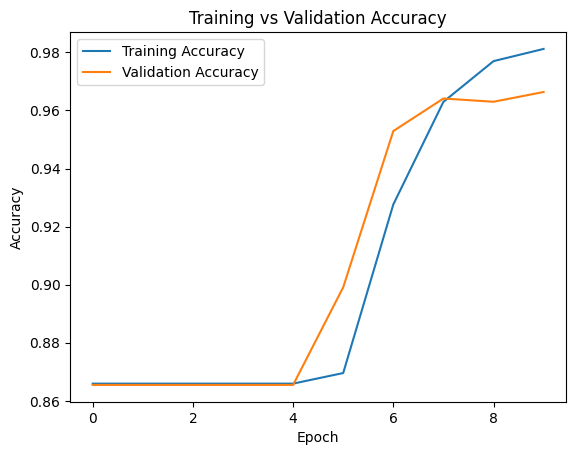

In [25]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

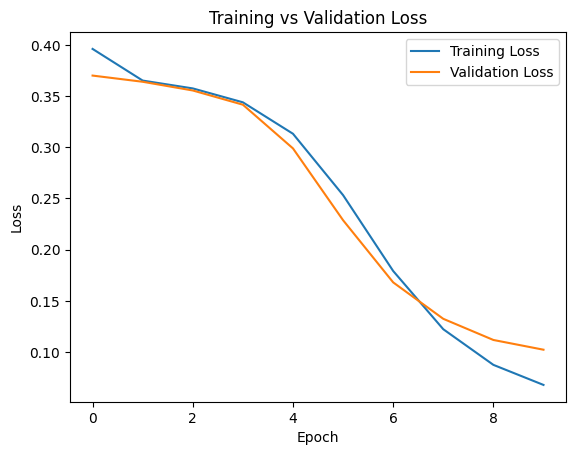

In [26]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

In [27]:
def predict_spam(message):
    probability = model.predict(
        tf.constant([message]),
        verbose=0
    )[0][0]

    if probability >= 0.5:
        prediction = "SPAM"
    else:
        prediction = "HAM"

    print("Message:", message)
    print("Prediction:", prediction)
    print("Spam probability:", f"{probability:.2%}")

In [28]:
predict_spam("Congratulations! You have won a free iPhone. Click here to claim your prize!")

Message: Congratulations! You have won a free iPhone. Click here to claim your prize!
Prediction: SPAM
Spam probability: 85.03%


In [29]:
predict_spam("Hey, are you coming to class tomorrow?")

Message: Hey, are you coming to class tomorrow?
Prediction: HAM
Spam probability: 4.25%


In [30]:
predict_spam("URGENT! You have been selected for a cash prize. Call now!")

Message: URGENT! You have been selected for a cash prize. Call now!
Prediction: SPAM
Spam probability: 83.09%


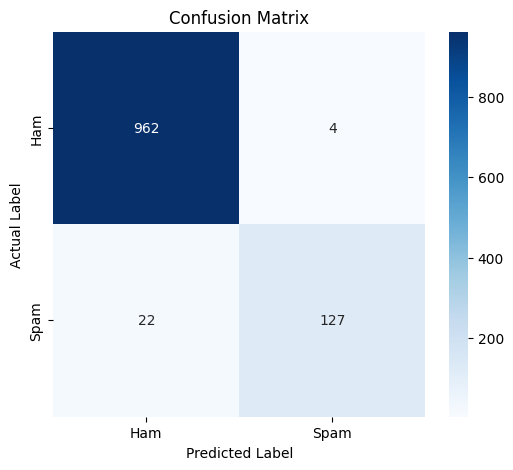

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

In [32]:
model.save("spam_detector.keras")

In [33]:
import os

print(os.path.getsize("spam_detector.keras"))

3420019
